# 01. Dataset exploratório com contratos, parcelas, liberações e aditivos

Este notebook usa exclusivamente:

- `vw_bi_contratos.csv`
- `vw_bi_parcelas.csv`
- `vw_tparcela_liberacao.csv`
- `vw_taditivovalor.csv`
- `vw_taditivoprazo.csv`

Ele cria relatórios de qualidade, consolida as fontes e gera snapshots por contrato e data de corte.

> Limitação: `vw_taditivovalor.csv` identifica os aditivos de valor, mas não possui uma coluna explícita com o valor aditado. Portanto, o notebook calcula quantidade e datas dos aditivos, mas não calcula valor aditado acumulado.


In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

FILES = [
    "vw_bi_contratos.csv",
    "vw_bi_parcelas.csv",
    "vw_tparcela_liberacao.csv",
    "vw_taditivovalor.csv",
    "vw_taditivoprazo.csv",
]


## 1. Pastas e carregamento

In [2]:
def find_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "raw").exists():
            return candidate
    return current.parent if current.name == "notebooks" else current

ROOT = find_root()
RAW = ROOT / "data" / "raw"
INTERIM = ROOT / "data" / "interim"
PROCESSED = ROOT / "data" / "processed"
QUALITY = ROOT / "reports" / "data_quality"
FIGURES = ROOT / "reports" / "figures"

for folder in [RAW, INTERIM, PROCESSED, QUALITY, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

missing = [name for name in FILES if not (RAW / name).exists()]
if missing:
    raise FileNotFoundError(f"Arquivos ausentes em {RAW}: {missing}")

print("Raiz do projeto:", ROOT)


Raiz do projeto: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras


In [3]:
def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def read_csv(name: str) -> pd.DataFrame:
    return pd.read_csv(RAW / name, low_memory=False, encoding="utf-8-sig")

contratos = read_csv("vw_bi_contratos.csv")
parcelas = read_csv("vw_bi_parcelas.csv")
liberacoes = read_csv("vw_tparcela_liberacao.csv")
aditivos_valor = read_csv("vw_taditivovalor.csv")
aditivos_prazo = read_csv("vw_taditivoprazo.csv")

datasets = {
    "contratos": contratos,
    "parcelas": parcelas,
    "liberacoes": liberacoes,
    "aditivos_valor": aditivos_valor,
    "aditivos_prazo": aditivos_prazo,
}

manifest = pd.DataFrame([{
    "arquivo": name,
    "linhas": len(datasets[key]),
    "colunas": datasets[key].shape[1],
    "tamanho_bytes": (RAW / name).stat().st_size,
    "sha256": sha256(RAW / name),
} for key, name in zip(datasets, FILES)])
manifest.to_csv(QUALITY / "manifesto_carga.csv", index=False, encoding="utf-8-sig")
manifest


,arquivo,linhas,colunas,tamanho_bytes,sha256
0,vw_bi_contratos.csv,87,26,31823,3a70ec89ee4e57cc6691bba80cb338d8001ba6638e445b...
1,vw_bi_parcelas.csv,13010,11,1323795,33ce2ca7b1f53f4d95428b431c46ca9c7f88a062f33867...
2,vw_tparcela_liberacao.csv,11918,8,632450,b77ba8cc895957e852ef543b85697fbff3912b59564ba2...
3,vw_taditivovalor.csv,271,10,35412,384a5614ec6766368935af3e761c773e52f70d8d147ade...
4,vw_taditivoprazo.csv,245,10,23844,338ec4b4799c694dbcdcb5f109add0173eba3f3b499ec5...


## 2. Padronização de tipos

In [4]:
DATE_SENTINELS = {"1900-01-01", "0000-00-00", "1899-12-30"}


def to_dates(df, columns):
    result = df.copy()
    for column in columns:
        if column in result.columns:
            values = result[column].astype("string").str.strip().mask(lambda s: s.isin(DATE_SENTINELS))
            result[column] = pd.to_datetime(values, errors="coerce")
    return result


def to_numbers(df, columns):
    result = df.copy()
    for column in columns:
        if column in result.columns:
            result[column] = pd.to_numeric(result[column], errors="coerce")
    return result

contratos = to_numbers(contratos, ["Id_contrato", "Valor_total_contrato", "Prazo_total", "Id_fornecedor"])
contratos = to_dates(contratos, [
    "Data_assinatura_contrato", "Data_conclusao_contrato", "Data_conclusao",
    "Data_proposta", "Data_Orcamento", "Data_OS", "Data_Paralisacao", "Data_Prev_Retomada"
])

parcelas = to_numbers(parcelas, ["id_parcela", "id_contrato", "valor_reajustado", "ordem_status", "valor_ja_liberado"])
parcelas = to_dates(parcelas, ["data_prevista_parcela", "data_efetiva", "data_liberacao"])

liberacoes = to_numbers(liberacoes, ["id_Contrato", "id_Parcela", "Abono_atraso", "Atraso_considerado", "Valor_total_liberado"])
liberacoes = to_dates(liberacoes, ["Data_efet_conclusao", "Data_liberação"])

aditivos_valor = to_numbers(aditivos_valor, ["idContrato"])
aditivos_valor = to_dates(aditivos_valor, ["Data_assinatura_TA_valor"])

aditivos_prazo = to_numbers(aditivos_prazo, ["idContrato", "Aditado_em_dias"])
aditivos_prazo = to_dates(aditivos_prazo, ["Data_termino_anterior", "Data_termino_nova", "Data_assinatura_ta_prazo"])

datasets = {
    "contratos": contratos, "parcelas": parcelas, "liberacoes": liberacoes,
    "aditivos_valor": aditivos_valor, "aditivos_prazo": aditivos_prazo,
}


## 3. Qualidade e cobertura das chaves

In [5]:
summary = pd.DataFrame([{
    "dataset": name,
    "linhas": len(df),
    "colunas": df.shape[1],
    "duplicidades": int(df.duplicated().sum()),
    "percentual_nulos": round(float(df.isna().mean().mean() * 100), 2),
} for name, df in datasets.items()])

column_quality = pd.concat([pd.DataFrame({
    "dataset": name,
    "coluna": df.columns,
    "tipo": df.dtypes.astype(str).values,
    "nulos": df.isna().sum().values,
    "percentual_nulos": (df.isna().mean().values * 100).round(2),
    "distintos": [df[c].nunique(dropna=True) for c in df.columns],
}) for name, df in datasets.items()], ignore_index=True)

summary.to_csv(QUALITY / "resumo_qualidade.csv", index=False, encoding="utf-8-sig")
column_quality.to_csv(QUALITY / "qualidade_colunas.csv", index=False, encoding="utf-8-sig")
display(summary)
display(column_quality.sort_values("percentual_nulos", ascending=False).head(20))


,dataset,linhas,colunas,duplicidades,percentual_nulos
0,contratos,87,26,0,16.36
1,parcelas,13010,11,8,1.53
2,liberacoes,11918,8,1,0.00
3,aditivos_valor,271,10,6,1.00
4,aditivos_prazo,245,10,0,0.00


,dataset,coluna,tipo,nulos,percentual_nulos,distintos
19,contratos,Data_Paralisacao,datetime64[us],84,96.55,3
20,contratos,Motivo_Paralisacao,str,84,96.55,3
21,contratos,Data_Prev_Retomada,datetime64[us],84,96.55,3
14,contratos,Data_proposta,datetime64[us],44,50.57,40
12,contratos,Data_conclusao,datetime64[us],26,29.89,61
1,contratos,Data_conclusao_contrato,datetime64[us],26,29.89,61
16,contratos,Data_OS,datetime64[us],9,10.34,75
45,aditivos_valor,Data_assinatura_TA_valor,datetime64[us],26,9.59,206
33,parcelas,data_liberacao,datetime64[us],1092,8.39,1547
32,parcelas,data_efetiva,datetime64[us],1092,8.39,1589


In [6]:
def id_set(series):
    return set(pd.to_numeric(series, errors="coerce").dropna().astype(int))

ids_contratos = id_set(contratos["Id_contrato"])
relations = [
    ("parcelas -> contratos", id_set(parcelas["id_contrato"]), ids_contratos),
    ("liberacoes -> contratos", id_set(liberacoes["id_Contrato"]), ids_contratos),
    ("aditivos valor -> contratos", id_set(aditivos_valor["idContrato"]), ids_contratos),
    ("aditivos prazo -> contratos", id_set(aditivos_prazo["idContrato"]), ids_contratos),
]
coverage = pd.DataFrame([{
    "relacao": name,
    "ids_origem": len(source),
    "ids_correspondentes": len(source & target),
    "cobertura_pct": round(100 * len(source & target) / max(len(source), 1), 2),
} for name, source, target in relations])
coverage.to_csv(QUALITY / "cobertura_relacionamentos.csv", index=False, encoding="utf-8-sig")
coverage


,relacao,ids_origem,ids_correspondentes,cobertura_pct
0,parcelas -> contratos,379,78,20.58
1,liberacoes -> contratos,372,77,20.70
2,aditivos valor -> contratos,86,59,68.60
3,aditivos prazo -> contratos,107,51,47.66


## 4. Consolidação das parcelas e liberações

In [7]:
parcelas_base = (
    parcelas.drop_duplicates()
    .sort_values(["id_contrato", "id_parcela"])
    .drop_duplicates(["id_contrato", "id_parcela"], keep="last")
)

liberacoes_base = (
    liberacoes.drop_duplicates()
    .groupby(["id_Contrato", "id_Parcela"], as_index=False)
    .agg(
        status_liberacao=("Status_liberacao", "last"),
        data_efetiva_conclusao=("Data_efet_conclusao", "max"),
        data_liberacao_real=("Data_liberação", "max"),
        abono_atraso=("Abono_atraso", "max"),
        atraso_considerado=("Atraso_considerado", "max"),
        valor_total_liberado=("Valor_total_liberado", "sum"),
    )
    .rename(columns={"id_Contrato": "id_contrato", "id_Parcela": "id_parcela"})
)

parcelas_liberacoes = parcelas_base.merge(
    liberacoes_base,
    on=["id_contrato", "id_parcela"],
    how="outer",
    validate="one_to_one",
    indicator=True,
)

parcelas_liberacoes["data_evento"] = (
    parcelas_liberacoes["data_liberacao_real"]
    .fillna(parcelas_liberacoes["data_efetiva_conclusao"])
    .fillna(parcelas_liberacoes["data_efetiva"])
)
parcelas_liberacoes["dias_atraso_parcela"] = (
    parcelas_liberacoes["data_efetiva_conclusao"] - parcelas_liberacoes["data_prevista_parcela"]
).dt.days

parcelas_liberacoes.to_parquet(INTERIM / "parcelas_liberacoes.parquet", index=False)
parcelas_liberacoes.head()


,id_parcela,id_contrato,tipo_de_parcela,status_da_parcela,nome_parcela,data_prevista_parcela,data_efetiva,data_liberacao,valor_reajustado,ordem_status,valor_ja_liberado,status_liberacao,data_efetiva_conclusao,data_liberacao_real,abono_atraso,atraso_considerado,valor_total_liberado,_merge,data_evento,dias_atraso_parcela
0,15,9,Serviços Originais,LIBERADA,1,2020-02-06,2020-11-27,2020-12-04,"53,265.81",99.00,0.00,LIBERADO,2020-11-27,2020-12-04,250.00,45.00,"53,265.81",both,2020-12-04,295.00
1,16,9,Serviços Originais,CANCELADA,2,2020-12-27,NaT,NaT,"53,265.81",99.00,0.00,NaN,NaT,NaT,NaN,NaN,NaN,left_only,NaT,NaN
2,17,9,Serviços Originais,CANCELADA,3,2021-01-26,NaT,NaT,"26,632.90",99.00,0.00,NaN,NaT,NaT,NaN,NaN,NaN,left_only,NaT,NaN
3,18,9,Serviços Originais,CANCELADA,4,2021-02-25,NaT,NaT,"79,898.71",99.00,0.00,NaN,NaT,NaT,NaN,NaN,NaN,left_only,NaT,NaN
4,19,9,Serviços Originais,CANCELADA,5,2021-03-27,NaT,NaT,"53,265.80",99.00,0.00,NaN,NaT,NaT,NaN,NaN,NaN,left_only,NaT,NaN


## 5. Consolidação dos aditivos

In [8]:
aditivos_prazo_eventos = (
    aditivos_prazo.drop_duplicates()
    .rename(columns={
        "idContrato": "id_contrato",
        "Data_assinatura_ta_prazo": "data_evento",
        "Aditado_em_dias": "dias_aditados",
        "Data_termino_nova": "data_termino_vigente",
    })
    [["id_contrato", "data_evento", "dias_aditados", "data_termino_vigente", "Status_aditivo_prazo"]]
    .dropna(subset=["id_contrato", "data_evento"])
)

aditivos_valor_eventos = (
    aditivos_valor.drop_duplicates()
    .rename(columns={
        "idContrato": "id_contrato",
        "Data_assinatura_TA_valor": "data_evento",
    })
    [["id_contrato", "data_evento", "Nome_do_aditivo", "Status_aditivo_valor", "status_criacao"]]
    .dropna(subset=["id_contrato", "data_evento"])
)

aditivos_prazo_eventos.to_parquet(INTERIM / "aditivos_prazo_eventos.parquet", index=False)
aditivos_valor_eventos.to_parquet(INTERIM / "aditivos_valor_eventos.parquet", index=False)


## 6. Datas de corte

A `data_corte` é formada somente por eventos realizados:

- liberação ou conclusão efetiva da parcela;
- assinatura de aditivo de prazo;
- assinatura de aditivo de valor.

A data prevista da parcela não cria snapshot. Ela permanece apenas como atributo para cálculo de atraso.


In [9]:
event_dates = pd.concat([
    parcelas_liberacoes[["id_contrato", "data_evento"]],
    aditivos_prazo_eventos[["id_contrato", "data_evento"]],
    aditivos_valor_eventos[["id_contrato", "data_evento"]],
], ignore_index=True)

calendar = (
    event_dates.dropna()
    .rename(columns={"data_evento": "data_corte"})
    .drop_duplicates()
    .sort_values(["id_contrato", "data_corte"])
)
calendar["id_contrato"] = calendar["id_contrato"].astype("int64")
calendar.head()


,id_contrato,data_corte
0,9,2020-12-04
12710,10,2019-02-13
5,10,2019-06-03
6,10,2020-10-14
7,10,2021-05-17


## 7. Features acumuladas até cada data de corte

In [10]:
financial_daily = (
    parcelas_liberacoes.dropna(subset=["data_evento"])
    .assign(qtd_parcelas=1, parcela_liberada=lambda d: d["data_liberacao_real"].notna().astype(int))
    .groupby(["id_contrato", "data_evento"], as_index=False)
    .agg(
        qtd_parcelas=("qtd_parcelas", "sum"),
        qtd_parcelas_liberadas=("parcela_liberada", "sum"),
        valor_liberado=("valor_total_liberado", "sum"),
        atraso_medio_parcela=("dias_atraso_parcela", "mean"),
        atraso_maximo_parcela=("dias_atraso_parcela", "max"),
    )
    .sort_values(["id_contrato", "data_evento"])
)
for c in ["qtd_parcelas", "qtd_parcelas_liberadas", "valor_liberado"]:
    financial_daily[c + "_acumulado"] = financial_daily.groupby("id_contrato")[c].cumsum()

prazo_daily = (
    aditivos_prazo_eventos.assign(qtd_aditivos_prazo=1)
    .groupby(["id_contrato", "data_evento"], as_index=False)
    .agg(
        qtd_aditivos_prazo=("qtd_aditivos_prazo", "sum"),
        dias_aditados=("dias_aditados", "sum"),
        data_termino_vigente=("data_termino_vigente", "max"),
    )
    .sort_values(["id_contrato", "data_evento"])
)
prazo_daily["qtd_aditivos_prazo_acumulado"] = prazo_daily.groupby("id_contrato")["qtd_aditivos_prazo"].cumsum()
prazo_daily["dias_aditados_acumulado"] = prazo_daily.groupby("id_contrato")["dias_aditados"].cumsum()

valor_daily = (
    aditivos_valor_eventos.assign(qtd_aditivos_valor=1)
    .groupby(["id_contrato", "data_evento"], as_index=False)
    .agg(qtd_aditivos_valor=("qtd_aditivos_valor", "sum"))
    .sort_values(["id_contrato", "data_evento"])
)
valor_daily["qtd_aditivos_valor_acumulado"] = valor_daily.groupby("id_contrato")["qtd_aditivos_valor"].cumsum()


In [11]:
def merge_asof_contract(left, right, right_date="data_evento"):
    left = left.copy()
    right = right.copy()
    left["id_contrato"] = pd.to_numeric(left["id_contrato"]).astype("int64")
    right["id_contrato"] = pd.to_numeric(right["id_contrato"]).astype("int64")
    return pd.merge_asof(
        left.sort_values(["data_corte", "id_contrato"]),
        right.sort_values([right_date, "id_contrato"]),
        left_on="data_corte", right_on=right_date, by="id_contrato",
        direction="backward", allow_exact_matches=True,
    )

snapshots = merge_asof_contract(calendar, financial_daily)
snapshots = merge_asof_contract(snapshots, prazo_daily)
snapshots = merge_asof_contract(snapshots, valor_daily)


## 8. Inclusão do cadastro de contratos e variáveis derivadas

In [12]:
contracts_master = contratos.rename(columns={
    "Id_contrato": "id_contrato",
    "Numero_contrato": "numero_contrato",
    "Classificacao_contrato": "tipo_obra",
    "Valor_total_contrato": "valor_total_contrato",
    "Prazo_total": "prazo_total_informado",
    "Id_fornecedor": "id_fornecedor",
    "Nome_fornecedor": "nome_fornecedor",
    "Status_Contrato": "status_contrato",
}).drop_duplicates("id_contrato")

snapshots = snapshots.merge(contracts_master, on="id_contrato", how="left", validate="many_to_one")
snapshots["percentual_financeiro_liberado"] = (
    snapshots["valor_liberado_acumulado"] / snapshots["valor_total_contrato"]
).where(snapshots["valor_total_contrato"].gt(0))
snapshots["dias_ate_termino_vigente"] = (snapshots["data_termino_vigente"] - snapshots["data_corte"]).dt.days
snapshots["dias_desde_os"] = (snapshots["data_corte"] - snapshots["Data_OS"]).dt.days
snapshots["flag_contrato_localizado"] = snapshots["numero_contrato"].notna().astype("int8")
snapshots["flag_percentual_financeiro_suspeito"] = (
    snapshots["percentual_financeiro_liberado"].lt(0)
    | snapshots["percentual_financeiro_liberado"].gt(1.5)
).astype("int8")

snapshots = snapshots.sort_values(["id_contrato", "data_corte"]).reset_index(drop=True)
assert not snapshots.duplicated(["id_contrato", "data_corte"]).any()


## 9. Dataset final e relatórios

In [13]:
drop_columns = [c for c in snapshots.columns if c == "data_evento"]
dataset = snapshots.drop(columns=drop_columns)

dataset.to_parquet(PROCESSED / "dataset_exploratorio_contratos.parquet", index=False)
dataset.to_csv(PROCESSED / "dataset_exploratorio_contratos.csv", index=False, encoding="utf-8-sig")

final_quality = pd.DataFrame({
    "metrica": [
        "snapshots", "contratos", "data_corte_minima", "data_corte_maxima",
        "duplicidades_contrato_data", "cobertura_cadastro_contrato_pct",
    ],
    "valor": [
        len(dataset), dataset["id_contrato"].nunique(), dataset["data_corte"].min(),
        dataset["data_corte"].max(), dataset.duplicated(["id_contrato", "data_corte"]).sum(),
        round(100 * dataset["flag_contrato_localizado"].mean(), 2),
    ],
})
final_quality.to_csv(QUALITY / "qualidade_dataset_exploratorio.csv", index=False, encoding="utf-8-sig")
final_quality


,metrica,valor
0,snapshots,7942
1,contratos,374
2,data_corte_minima,0023-02-26 00:00:00
3,data_corte_maxima,8202-08-11 00:00:00
4,duplicidades_contrato_data,0
5,cobertura_cadastro_contrato_pct,14.49


## 10. Visualização rápida

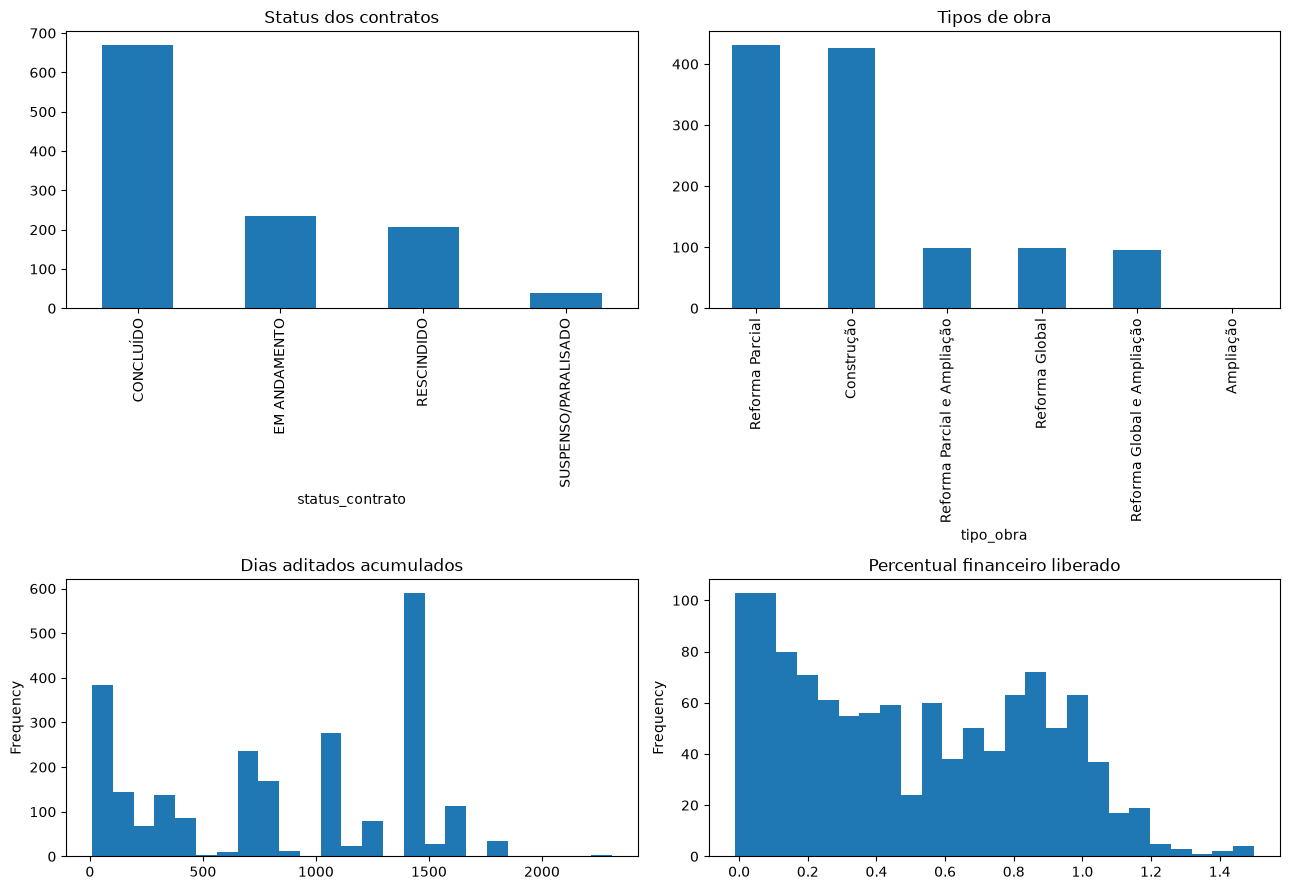

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

dataset["status_contrato"].value_counts().head(10).plot(kind="bar", ax=axes[0, 0], title="Status dos contratos")
dataset["tipo_obra"].value_counts().head(10).plot(kind="bar", ax=axes[0, 1], title="Tipos de obra")
dataset["dias_aditados_acumulado"].dropna().plot(kind="hist", bins=25, ax=axes[1, 0], title="Dias aditados acumulados")
dataset["percentual_financeiro_liberado"].dropna().clip(upper=1.5).plot(kind="hist", bins=25, ax=axes[1, 1], title="Percentual financeiro liberado")

plt.tight_layout()
plt.savefig(FIGURES / "visao_geral_dataset.png", dpi=150, bbox_inches="tight")
plt.show()
